# 03 · Editing: trim, cut, select, combine

Every step returns a new object; the original is never changed, and the step is written to `history`.

In [1]:
import matplotlib.pyplot as plt
import spectrum_toolkit as stk

def show(*items, title=''):
    """Quick plot of spectra or collections (a proper stk.plot comes later)."""
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for item in items:
        for sp in (list(item) if isinstance(item, stk.SpectrumCollection) else [item]):
            ax.plot(sp.x, sp.y, lw=1)
    ax.set_title(title)
    plt.show()

## 1. Trim and cut

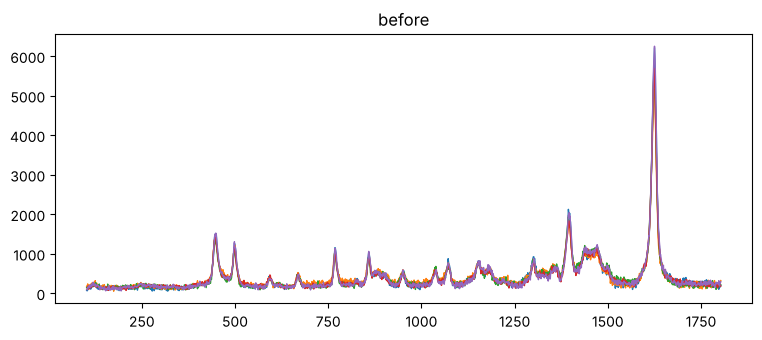

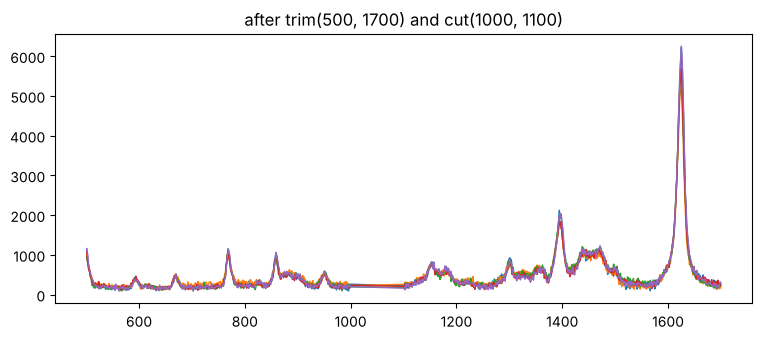

({'step': 'trim', 'lo': 500, 'hi': 1700, 'points_removed': 401},
 {'step': 'cut', 'lo': 1000, 'hi': 1100, 'points_removed': 85})

In [2]:
c = stk.load('../data/MB 10-4M.xlsx', verbose=False)
t = c.trim(500, 1700)          # keep 500-1700
t2 = t.cut(1000, 1100)         # remove 1000-1100
show(c, title='before'); show(t2, title='after trim(500, 1700) and cut(1000, 1100)')
t2.history

## 2. Select and drop spectra

By number (0 = first, -1 = last) or by name.

In [3]:
print(c.names)
print(c.drop('3').names)
print(c.select(0, -1).names)

('1', '2', '3', '4', '5')
('1', '2', '4', '5')
('1', '5')


## 3. Combine: same x values, some points missing

In `CV+RhB+MB.xlsx` all 35 pairs use one x grid, but two columns have rows deleted. Only the x values every spectrum has are kept; no value is changed.

In [4]:
pairs = stk.load('../data/CV+RhB+MB.xlsx', verbose=False)   # a list of 35 spectra
m = stk.combine(pairs)
print(m.meta['axis_report'])

Combined: 35 spectra, 618 points each, x 101.406 to 1801.69
  - Same x values, but not all spectra have all of them; kept the 618 x values every spectrum has (102 point(s) dropped in total, no values changed).
The x values match, but some spectra are longer or have points missing.
Common range: 101.406 to 1801.69. Reference x: spectrum 0 (Spectrum 1).
  #  name                         points     x from       x to     step  overlap    shift
  0  Spectrum 1                      621    101.406    1801.69    2.736    100%         0
  1  Spot2                           621    101.406    1801.69    2.736    100%         0
  2  Spot3                           621    101.406    1801.69    2.736    100%         0
  3  Spot4                           621    101.406    1801.69    2.736    100%         0
  4  Spot5                           621    101.406    1801.69    2.736    100%         0
  5  Spot6                           619    101.406    1801.69    2.737    100%         0
  6  Spectrum 7 

## 4. Combine files whose x axes differ

CV, RhB and MB were measured with slightly different calibrations. Without permission, `combine` stops and shows the table:

In [5]:
files = ['../data/CV10-4M.xlsx', '../data/RhB10-4M.xlsx', '../data/MB 10-4M.xlsx']
try:
    stk.combine(*files)
except ValueError as e:
    print(e)

The x axes of these spectra are not the same, so they cannot be stacked directly.
The x axes differ; combining them needs interpolation.
Common range: 103.045 to 1802.61. Reference x: spectrum 0 (CV10-4M: Spectrum 1).
  #  name                         points     x from       x to     step  overlap    shift
  0  CV10-4M: Spectrum 1            1424     101.91    1802.78    1.191    100%     0.568
  1  CV10-4M: Spectrum 2            1424     101.91    1802.78    1.191    100%     0.568
  2  CV10-4M: Spectrum 3            1424     101.91    1802.78    1.191    100%     0.568
  3  CV10-4M: Spectrum 4            1424     101.91    1802.78    1.191    100%     0.568
  4  CV10-4M: Spectrum 5            1424     101.91    1802.78    1.191    100%     0.568
  5  CV10-4M: Spectrum 6            1424     101.91    1802.78    1.191    100%     0.568
  6  CV10-4M: Spectrum 7            1424     101.91    1802.78    1.191    100%     0.568
  7  CV10-4M: Spectrum 8            1424     101.91    1802.78

With `interpolate=True` every spectrum is put on one x axis (linear interpolation, common range only). `reference=` chooses whose axis.

Combined: 30 spectra, 1422 points each, x 103.258 to 1801.72
  - x axes differ (largest shift 0.568); interpolated every spectrum (linear) onto the x axis of 'CV10-4M: Spectrum 1', 1422 points from 103.258 to 1801.72.


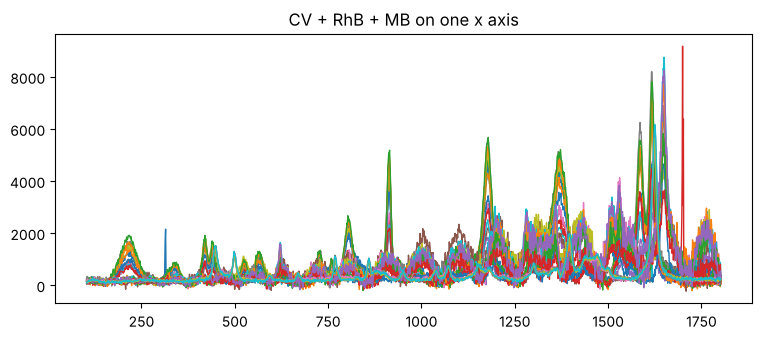

In [6]:
all3 = stk.combine(*files, interpolate=True)
show(all3, title='CV + RhB + MB on one x axis')

## 5. A mix: collections, single spectra, different steps

`CV+RhB+MB.xlsx` has a step of 2.74 cm⁻¹, the others 1.19. The coarser axis is used, so nothing is invented.

In [7]:
everything = stk.combine(all3, m, interpolate=True)
everything

Combined: 65 spectra, 617 points each, x 104.428 to 1801.69
  - x axes differ (largest shift 1.85); interpolated every spectrum (linear) onto the x axis of 'Spectrum 1', 617 points from 104.428 to 1801.69.
  - Note: 30 spectra had a finer step (1.19) than the reference (2.74); their fine detail is reduced to the reference's step.


SpectrumCollection(65 spectra × 617 points, x 104.428 to 1801.69)

## 6. Interpolation methods

`interpolate=` takes a method name. All pass through the measured points; they differ between them.

- `linear`: straight lines; never overshoots (default)
- `quadratic`, `cubic`: smooth splines; can overshoot next to sharp peaks
- `pchip`: smooth and never overshoots; good for sharp peaks
- `akima`: smooth, little overshoot

Below: one RhB spectrum around a peak, interpolated each way.

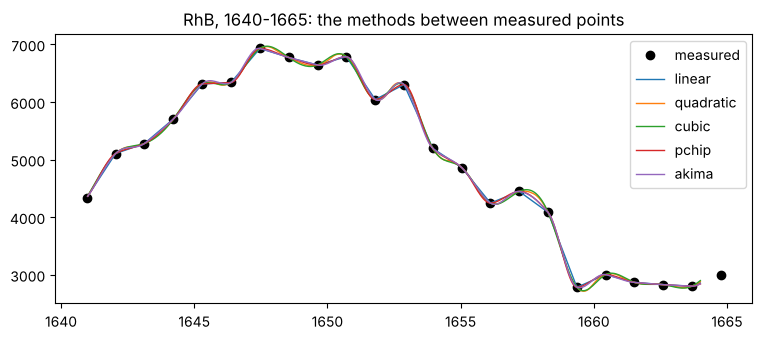

In [8]:
import numpy as np
rhb = stk.load('../data/RhB10-4M.xlsx', verbose=False)[0]
fig, ax = plt.subplots(figsize=(9, 3.5))
win = (rhb.x > 1640) & (rhb.x < 1665)
ax.plot(rhb.x[win], rhb.y[win], 'ko', label='measured')
fine = np.linspace(1641, 1664, 400)
for m in stk.edit.METHODS:
    ax.plot(fine, stk.resample(rhb, fine, method=m).y, lw=1, label=m)
ax.legend(); ax.set_title('RhB, 1640-1665: the methods between measured points')
plt.show()